<a href="https://colab.research.google.com/github/shashikawka/268452H-CS5998-Capstone-Project/blob/main/04_autoencoder_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Temporal Autoencoder for Anomaly Detection

This notebook implements a window based autoencoder for detecting
unusual behaviour in the MetroPT-3 railway APU sensor dataset.

The model uses windows of 60 observations with 15 sensor features.

I used the pre-failure data for training and the validation data to select the model settings and anomaly threshold. The evaluation data is kept separately to test how well the model performs.

###Step 1 : Data Preperation

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42) # Reproducibility

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs: []


In [4]:
#Load data

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

# Load temporal windows
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training window:", X_train_windows.shape)
print("Validation window:", X_val_windows.shape)
print("Evaluation window:", X_eval_windows.shape)

print("\nData type:", X_train_windows.dtype)

Training window: (41938, 60, 15)
Validation window: (13749, 60, 15)
Evaluation window: (94307, 60, 15)

Data type: float32


In [ ]:
#Verify the window data
print("Training shape valid:",
      X_train_windows.shape[1:] == (60, 15))

print("Validation shape valid:",
      X_val_windows.shape[1:] == (60, 15))

print("Evaluation shape valid:",
      X_eval_windows.shape[1:] == (60, 15))

print("\nFirst training window:", X_train_windows[0].shape)

print("Training values finite:",
      np.isfinite(X_train_windows).all())

print("Validation values finite:",
      np.isfinite(X_val_windows).all())

print("Evaluation values finite:",
      np.isfinite(X_eval_windows).all())

Training shape valid: True
Validation shape valid: True
Evaluation shape valid: True

First training window: (60, 15)
Training values finite: True
Validation values finite: True
Evaluation values finite: True


###Step 2 : Build the Autoencoder Architecture

In [ ]:
#2.1 Cereate Auto Encoder
#simple dense autoencoder. It uses all observations within a window, but it does not explicitly model sequence order like an LSTM.
# Each window contains 60 observations and 15 features
window_size = X_train_windows.shape[1]
n_features = X_train_windows.shape[2]

input_dim = window_size * n_features

# Build the autoencoder
autoencoder = models.Sequential([
    layers.Input(shape=(window_size, n_features)),

    # Convert the window into a single vector
    layers.Flatten(),

    # Encoder
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),

    # Bottleneck
    layers.Dense(32, activation='relu'),

    # Decoder
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(input_dim, activation='linear'),

    # Restore the original window shape
    layers.Reshape((window_size, n_features))
])

# Configure the model
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse'
)

# Display the architecture
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 900)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       115,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 900)            │       116,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 60, 15)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,196 (985.14 KB)

 Trainable params: 252,196 (985.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#2.2 Create a model
# Test the model using one training window
sample_window = np.asarray(X_train_windows[:1])

reconstructed_window = autoencoder.predict(
    sample_window,
    verbose=0
)

print("Original window shape:", sample_window.shape)
print("Reconstructed window shape:", reconstructed_window.shape)

Original window shape: (1, 60, 15)
Reconstructed window shape: (1, 60, 15)


##### OBSERVATION:
##### I created a dense autoencoder using the 60 observation windows.
##### Each window has 15 sensor features, giving 900 input values.
##### The encoder reduces these values to a 32-value bottleneck,
##### and the decoder tries to reconstruct the original window.
##### I used MSE to measure the reconstruction error.
##### The model has not been trained yet.

###Step 3 : Train the Autoencoder

In [ ]:
#3.1 train the model
# Stop training if validation loss does not improve for 5 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the autoencoder
history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=30,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAutoencoder training completed.")
print("Epochs completed:", len(history.history['loss']))
print("Best validation loss:", min(history.history['val_loss']))

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.1914 - val_loss: 0.1709
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0756 - val_loss: 0.1405
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0666 - val_loss: 0.1308
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0628 - val_loss: 0.1311
Epoch 5/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0601 - val_loss: 0.1271
Epoch 6/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0576 - val_loss: 0.1263
Epoch 7/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0556 - val_loss: 0.1212
Epoch 8/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0536 - val_loss: 0.1193
Epoch 9/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0518 - val_loss: 0.1163
Epoch 10/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0502 - val_loss: 0.1159
Epoch 11/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0487 - val_loss: 0.1105
Epoch 12/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 

##### OBSERVATIONS:
##### I trained the autoencoder using the training windows and used the validation windows to monitor its reconstruction loss.
##### I set the maximum training epochs to 30 and used early stopping to stop training if the validation loss did not improve.
##### After training, I will compare the training and validation loss curves to check how well the model learned.

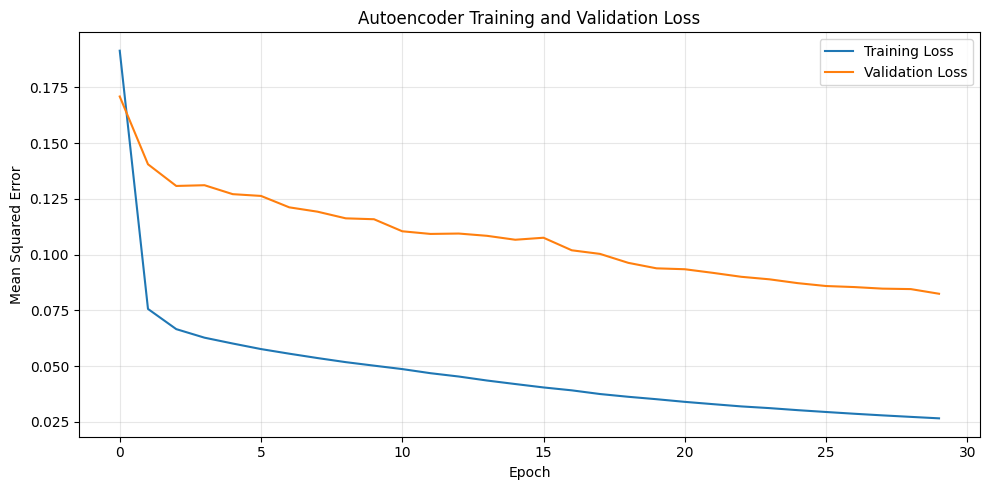

<Figure size 640x480 with 0 Axes>

In [ ]:
#3.2 Visualize training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Training_And_Valisation_Loss.png',
    dpi=300,
    bbox_inches='tight'
)

##### OBESERVATIONS:
##### The autoencoder completed all 30 training epochs. The training loss decreased from 0.0260 to 0.0189.
##### The validation loss also decreased, with the lowest value of 0.0675 recorded at epoch 29.
##### The validation loss remained higher than the training loss.
##### This may be due to differences in sensor behaviour between the training and validation periods.
##### Further evaluation is needed to check anomaly detection performance.

In [ ]:
#3.3 Continue training for up to 20 more epochs

# Continue training the existing autoencoder
additional_history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=20,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAdditional training completed.")
print("Additional epochs:", len(additional_history.history['loss']))
print("Best additional validation loss:",
      min(additional_history.history['val_loss']))

Epoch 1/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0260 - val_loss: 0.0803
Epoch 2/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0255 - val_loss: 0.0792
Epoch 3/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0248 - val_loss: 0.0791
Epoch 4/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.0244 - val_loss: 0.0778
Epoch 5/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0239 - val_loss: 0.0776
Epoch 6/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0235 - val_loss: 0.0778
Epoch 7/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0231 - val_loss: 0.0769
Epoch 8/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0227 - val_loss: 0.0771
Epoch 9/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0224 - val_loss: 0.0766
Epoch 10/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0220 - val_loss: 0.0763
Epoch 11/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0218 - val_loss: 0.0748
Epoch 12/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 

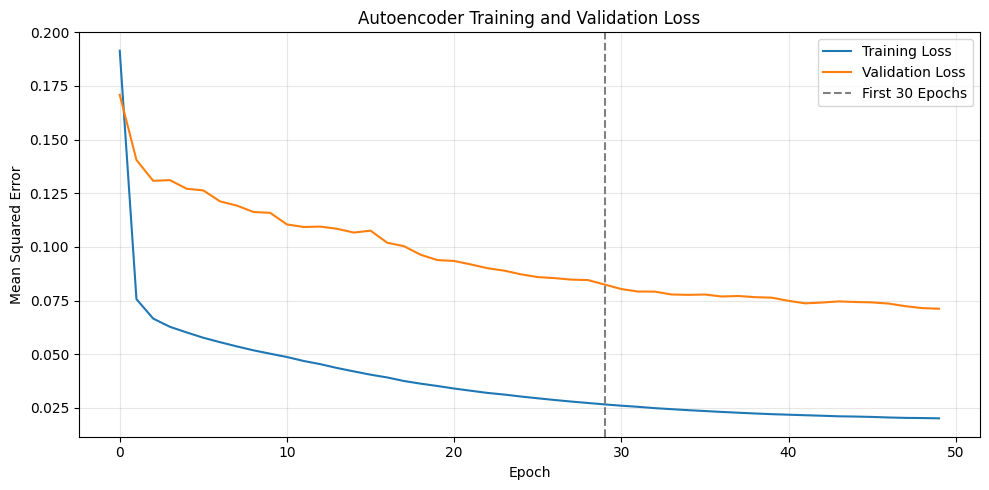

Total epochs: 50
Best validation loss: 0.07117723673582077


In [ ]:
#3.4 Plot the complete training history

# Combine the original and additional training results
all_train_loss = (
    history.history['loss'] +
    additional_history.history['loss']
)

all_val_loss = (
    history.history['val_loss'] +
    additional_history.history['val_loss']
)

plt.figure(figsize=(10, 5))

plt.plot(all_train_loss, label='Training Loss')
plt.plot(all_val_loss, label='Validation Loss')

plt.axvline(
    x=29,
    color='gray',
    linestyle='--',
    label='First 30 Epochs'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Total epochs:", len(all_train_loss))
print("Best validation loss:", min(all_val_loss))

##### OBSERVATIONS:
##### I first trained the autoencoder for 30 epochs.
##### Since the validation loss was still decreasing, I continued training for another 20 epochs.
##### The validation loss improved from 0.0825 to 0.0712. The training loss also decreased to around 0.0201.
##### The validation loss is still higher than the training loss. I will now evaluate the model using reconstruction errors.

###Step 5: Save trained model

In [ ]:
from pathlib import Path
import json

# Create a folder for autoencoder results
autoencoder_dir = data_dir.parent / 'autoencoder_results'
autoencoder_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model
autoencoder.save(autoencoder_dir / 'autoencoder_model.keras')

# Save training history
training_history = {
    'loss': [float(x) for x in all_train_loss],
    'val_loss': [float(x) for x in all_val_loss]
}

with open(autoencoder_dir / 'training_history.json', 'w') as f:
    json.dump(training_history, f, indent=4)

print("Model saved:", autoencoder_dir / 'autoencoder_model.keras')
print("Training history saved successfully.")

Model saved: /content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results/autoencoder_model.keras
Training history saved successfully.


###Step 5: Verify saved model

In [ ]:
# Load the saved model
loaded_autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

# Check its output shape
sample = np.asarray(X_val_windows[:1])

prediction = loaded_autoencoder.predict(
    sample,
    verbose=0
)

print("Input shape:", sample.shape)
print("Output shape:", prediction.shape)
print("Model loaded successfully.")

Input shape: (1, 60, 15)
Output shape: (1, 60, 15)
Model loaded successfully.


##### OBSERVATIONS:
##### I saved the trained autoencoder and its training history
##### to Google Drive so I can reuse them without retraining.
##### I also loaded the saved model and checked its output shape.

###Step 6 : Calculate Reconstruction Errors

In [10]:
#4.1 Calculate Reconstruction Erorrs
def calculate_reconstruction_errors(model, windows, batch_size=256):

    errors = []

    for start in range(0, len(windows), batch_size):

        batch = np.asarray(
            windows[start:start + batch_size]
        )

        reconstructed = model.predict(
            batch,
            verbose=0
        )

        batch_errors = np.mean(
            (batch - reconstructed) ** 2,
            axis=(1, 2)
        )

        errors.append(batch_errors)

    return np.concatenate(errors)


# Calculate reconstruction errors
train_errors = calculate_reconstruction_errors(
    autoencoder, X_train_windows
)

val_errors = calculate_reconstruction_errors(
    autoencoder, X_val_windows
)

eval_errors = calculate_reconstruction_errors(
    autoencoder, X_eval_windows
)

print("Training errors:", train_errors.shape)
print("Validation errors:", val_errors.shape)
print("Evaluation errors:", eval_errors.shape)

Training errors: (41938,)
Validation errors: (13749,)
Evaluation errors: (94307,)


In [ ]:
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

###Step 7 : Analyze Reconstruction Errors

In [17]:
autoencoder_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results')
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

In [18]:
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

In [19]:
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training:", X_train_windows.shape)
print("Validation:", X_val_windows.shape)
print("Evaluation:", X_eval_windows.shape)

Training: (41938, 60, 15)
Validation: (13749, 60, 15)
Evaluation: (94307, 60, 15)


In [20]:
#Calculate reconstruction error statistics
error_summary = pd.DataFrame({
    'Training': pd.Series(train_errors),
    'Validation': pd.Series(val_errors),
    'Evaluation': pd.Series(eval_errors)
})

print(error_summary.describe().round(4))

         Training  Validation  Evaluation
count  41938.0000  13749.0000  94307.0000
mean       0.0198      0.0712      0.1164
std        0.0436      0.2260      0.3504
min        0.0004      0.0004      0.0004
25%        0.0007      0.0011      0.0052
50%        0.0056      0.0107      0.0279
75%        0.0267      0.0425      0.0596
max        1.3935      5.7972      5.3711


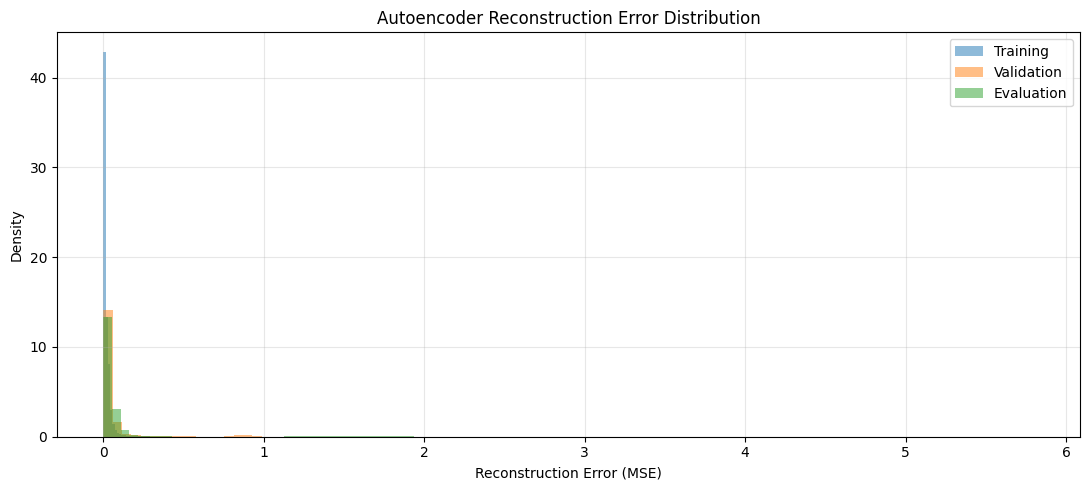

In [21]:
#Plot reconstruction error distributions
plt.figure(figsize=(11, 5))

plt.hist(train_errors, bins=100, alpha=0.5,
         density=True, label='Training')

plt.hist(val_errors, bins=100, alpha=0.5,
         density=True, label='Validation')

plt.hist(eval_errors, bins=100, alpha=0.5,
         density=True, label='Evaluation')

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density')
plt.title('Autoencoder Reconstruction Error Distribution')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

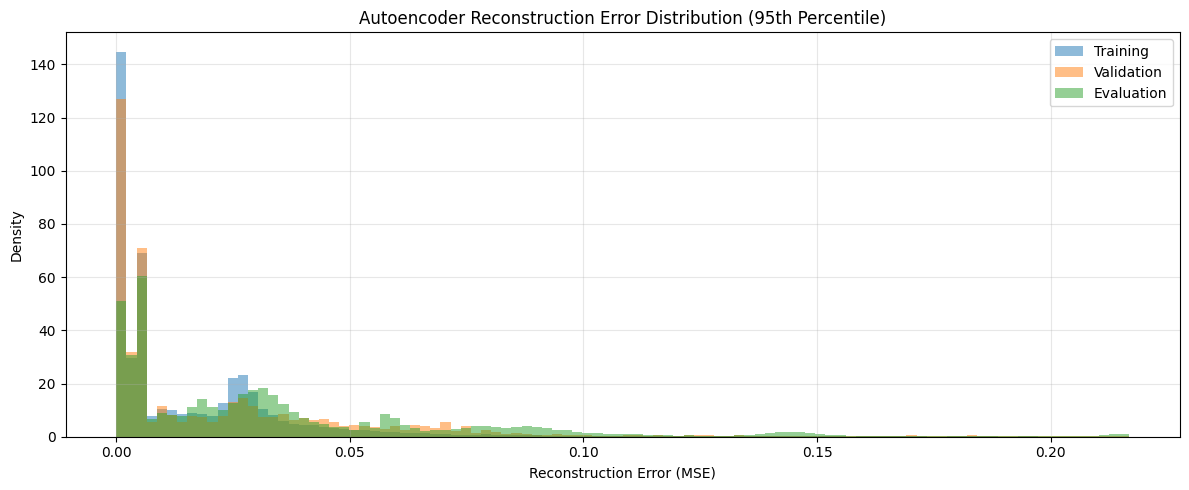

Visualization upper limit: 0.2168


<Figure size 640x480 with 0 Axes>

In [22]:
#Improve the graph
# Calculate a common upper limit for visualization
all_errors = np.concatenate([
    train_errors,
    val_errors,
    eval_errors
])

plot_limit = np.percentile(all_errors, 95)

plt.figure(figsize=(12, 5))

plt.hist(
    train_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Training'
)

plt.hist(
    val_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Validation'
)

plt.hist(
    eval_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Evaluation'
)

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density')
plt.title('Autoencoder Reconstruction Error Distribution (95th Percentile)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Error_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)

print("Visualization upper limit:", round(plot_limit, 4))

##### OBSERVATIONS:
##### The training dataset has the lowest average reconstruction error, followed by the validation and evaluation datasets.
##### Most reconstruction errors are relatively small, but a few windows have much higher errors.
##### These high values made the original histogram difficult to read.
##### I adjusted the visualization to show the main distribution more clearly.
##### The evaluation errors are generally higher than the training errors,but further analysis is needed to check whether they relate to failures.

##Step 8 : Select Anomaly Threshold

In [23]:
# Select threshold using validation reconstruction errors
ae_threshold = np.percentile(val_errors, 99)

print("Autoencoder anomaly threshold:", round(ae_threshold, 6))

Autoencoder anomaly threshold: 0.937345


In [24]:
# Identify anomalies using the selected threshold
train_predictions = train_errors > ae_threshold
val_predictions = val_errors > ae_threshold
eval_predictions = eval_errors > ae_threshold

# Calculate anomaly counts and percentages
for name, predictions in [
    ('Training', train_predictions),
    ('Validation', val_predictions),
    ('Evaluation', eval_predictions)
]:
    count = np.sum(predictions)
    percentage = np.mean(predictions) * 100

    print(f"{name}: {count:,} anomalies ({percentage:.2f}%)")

Training: 12 anomalies (0.03%)
Validation: 138 anomalies (1.00%)
Evaluation: 4,376 anomalies (4.64%)


In [25]:
# Save threshold and anomaly predictions
np.save(autoencoder_dir / 'ae_threshold.npy', ae_threshold)

np.save(autoencoder_dir / 'train_predictions.npy', train_predictions)
np.save(autoencoder_dir / 'val_predictions.npy', val_predictions)
np.save(autoencoder_dir / 'eval_predictions.npy', eval_predictions)

print("Autoencoder threshold and predictions saved successfully.")

Autoencoder threshold and predictions saved successfully.


##### OBSERVATIONS:
##### I selected an anomaly threshold of 0.937345 using the 99th percentile of the validation reconstruction errors.
##### The model identified 12 anomalous training windows, 138 validation windows and 4,376 evaluation windows.
##### The evaluation dataset had the highest anomaly percentage at 4.64%.
##### I will now check how these anomalies relate to the documented failure periods.

##Step 9 : Evaluate anomalies during failure periods

In [26]:
# Load evaluation metadata
eval_metadata = pd.read_csv(
    data_dir / 'eval_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

# Load the indices of the last observation in each window
eval_window_end_indices = np.load(
    data_dir / 'eval_window_end_indices.npy'
)

print("Evaluation metadata:", eval_metadata.shape)
print("Evaluation window indices:", eval_window_end_indices.shape)
print("Autoencoder predictions:", eval_predictions.shape)

print("\nMetadata columns:")
print(eval_metadata.columns.tolist())

Evaluation metadata: (954384, 3)
Evaluation window indices: (94307,)
Autoencoder predictions: (94307,)

Metadata columns:
['timestamp', 'segment_id', 'failure_period']


In [28]:
print("Evaluation metadata rows:", len(eval_metadata))
print("Metadata index range:",
      eval_metadata.index.min(),
      eval_metadata.index.max())

print("\nWindow indices:")
print("Count:", len(eval_window_end_indices))
print("Minimum:", eval_window_end_indices.min())
print("Maximum:", eval_window_end_indices.max())

print("\nFirst 5 window indices:")
print(eval_window_end_indices[:5])

print("\nFirst 5 metadata indices:")
print(eval_metadata.index[:5].tolist())

print("\nLast 5 metadata indices:")
print(eval_metadata.index[-5:].tolist())

print("\nPredictions:", len(eval_predictions))

Evaluation metadata rows: 954384
Metadata index range: 562564 1516947

Window indices:
Count: 94307
Minimum: 562623
Maximum: 1516947

First 5 window indices:
[562623 562633 562643 562653 562714]

First 5 metadata indices:
[562564, 562565, 562566, 562567, 562568]

Last 5 metadata indices:
[1516943, 1516944, 1516945, 1516946, 1516947]

Predictions: 94307


In [29]:
# Check that the number of indices matches the predictions
assert len(eval_window_end_indices) == len(eval_predictions)

# Check that all window indices exist in the metadata
assert np.isin(
    eval_window_end_indices,
    eval_metadata.index
).all()

# Get metadata using the original dataset index labels
eval_window_metadata = eval_metadata.loc[
    eval_window_end_indices
].copy()

# Add reconstruction errors and anomaly predictions
eval_window_metadata['reconstruction_error'] = eval_errors
eval_window_metadata['ae_anomaly'] = eval_predictions

print("Window-level evaluation data:", eval_window_metadata.shape)

print(
    eval_window_metadata[
        ['timestamp', 'reconstruction_error', 'ae_anomaly']
    ].head()
)

Window-level evaluation data: (94307, 5)
                 timestamp  reconstruction_error  ae_anomaly
562623 2020-04-18 00:11:52              0.079310       False
562633 2020-04-18 00:13:53              0.078905       False
562643 2020-04-18 00:15:54              0.079388       False
562653 2020-04-18 00:17:55              0.075551       False
562714 2020-04-18 00:33:44              1.157577        True


##### Observation:
##### The saved window indices refer to the original dataset indices.
##### I used .loc[] to match each window with its ending timestamp.
##### I also added the reconstruction errors and anomaly predictions to the evaluation metadata for further analysis.

In [30]:
#Evaluate the four failure periods
# Define the documented failure periods
failure_periods = [
    ('Failure 1', '2020-04-18 00:00:00', '2020-04-18 23:59:00'),
    ('Failure 2', '2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    ('Failure 3', '2020-06-05 10:00:00', '2020-06-07 14:30:00'),
    ('Failure 4', '2020-07-15 14:30:00', '2020-07-15 19:00:00')
]

failure_results = []

for name, start, end in failure_periods:

    # Select windows ending within the failure period
    failure_windows = eval_window_metadata[
        (eval_window_metadata['timestamp'] >= pd.Timestamp(start)) &
        (eval_window_metadata['timestamp'] <= pd.Timestamp(end))
    ]

    total_windows = len(failure_windows)
    anomaly_count = int(failure_windows['ae_anomaly'].sum())

    anomaly_percentage = (
        anomaly_count / total_windows * 100
        if total_windows > 0 else 0
    )

    failure_results.append({
        'Failure': name,
        'Total Windows': total_windows,
        'Anomalous Windows': anomaly_count,
        'Anomaly Percentage': round(anomaly_percentage, 2)
    })

failure_results_df = pd.DataFrame(failure_results)

print(failure_results_df.to_string(index=False))

  Failure  Total Windows  Anomalous Windows  Anomaly Percentage
Failure 1            855                851               99.53
Failure 2            236                236              100.00
Failure 3           1719               1719              100.00
Failure 4            156                  0                0.00


##### Observation:
##### The autoencoder identified almost all windows in the first three documented failure periods as anomalies.
##### Failure 1 had an anomaly rate of 99.53%, while Failures 2 and 3 had anomaly rates of 100%.
##### However, no anomalous windows were detected in Failure 4.
##### This shows that the model responds differently to the four failure periods.
##### Need to check the anomaly rate outside failure periods to better understand the model's performance.

In [31]:
# Identify windows ending within documented failure periods
failure_mask = pd.Series(
    False,
    index=eval_window_metadata.index
)

for name, start, end in failure_periods:

    failure_mask |= (
        (eval_window_metadata['timestamp'] >= pd.Timestamp(start)) &
        (eval_window_metadata['timestamp'] <= pd.Timestamp(end))
    )

# Separate windows inside and outside failure periods
inside_failure = eval_window_metadata.loc[failure_mask]
outside_failure = eval_window_metadata.loc[~failure_mask]

# Calculate anomaly counts
inside_anomalies = int(inside_failure['ae_anomaly'].sum())
outside_anomalies = int(outside_failure['ae_anomaly'].sum())

# Calculate anomaly percentages
inside_rate = inside_anomalies / len(inside_failure) * 100
outside_rate = outside_anomalies / len(outside_failure) * 100

print("Inside failure periods:")
print("Total windows:", len(inside_failure))
print("Anomalous windows:", inside_anomalies)
print("Anomaly percentage:", round(inside_rate, 2), "%")

print("\nOutside failure periods:")
print("Total windows:", len(outside_failure))
print("Anomalous windows:", outside_anomalies)
print("Anomaly percentage:", round(outside_rate, 2), "%")

Inside failure periods:
Total windows: 2966
Anomalous windows: 2806
Anomaly percentage: 94.61 %

Outside failure periods:
Total windows: 91341
Anomalous windows: 1570
Anomaly percentage: 1.72 %


##### Observation:
##### The autoencoder identified 94.61% of the windows within the documented failure periods as anomalies.
##### Outside these periods, the anomaly rate was 1.72%.
##### This shows that the model detects more unusual behaviour during the documented failure periods. were also identified outside the failure periods.
##### Further analysis is needed to understand these results.

In [32]:
# Check the first detected anomaly during each failure period
detection_results = []

for name, start, end in failure_periods:

    start_time = pd.Timestamp(start)
    end_time = pd.Timestamp(end)

    # Select windows ending within the failure period
    failure_windows = eval_window_metadata[
        (eval_window_metadata['timestamp'] >= start_time) &
        (eval_window_metadata['timestamp'] <= end_time)
    ].sort_values('timestamp')

    # Select anomalous windows
    detected_windows = failure_windows[
        failure_windows['ae_anomaly']
    ]

    if len(detected_windows) > 0:

        first_detection = detected_windows['timestamp'].iloc[0]

        detection_delay = (
            first_detection - start_time
        ).total_seconds() / 60

        status = 'Detected'

    else:

        first_detection = pd.NaT
        detection_delay = np.nan
        status = 'Not Detected'

    detection_results.append({
        'Failure': name,
        'Status': status,
        'First Detection': first_detection,
        'Detection Delay (minutes)': round(detection_delay, 2)
        if pd.notna(detection_delay) else np.nan
    })

detection_results_df = pd.DataFrame(detection_results)

print(detection_results_df.to_string(index=False))

  Failure       Status     First Detection  Detection Delay (minutes)
Failure 1     Detected 2020-04-18 00:33:44                      33.73
Failure 2     Detected 2020-05-29 23:30:37                       0.62
Failure 3     Detected 2020-06-05 10:01:23                       1.38
Failure 4 Not Detected                 NaT                        NaN


##### Observation:
##### The autoencoder detected anomalies during three of the four documented failure periods.
##### Failure 1 was first detected after 33.73 minutes.
##### Failures 2 and 3 were detected after 0.62 and 1.38 minutes.
##### No anomalies were detected during Failure 4.
##### These results show detection after the failure started, so I will also check for possible warnings before each failure.

In [33]:
# Check anomalies during the 24 hours before each failure
pre_failure_results = []

for name, start, end in failure_periods:

    start_time = pd.Timestamp(start)
    pre_start = start_time - pd.Timedelta(hours=24)

    # Select windows ending before the failure starts
    pre_failure_windows = eval_window_metadata[
        (eval_window_metadata['timestamp'] >= pre_start) &
        (eval_window_metadata['timestamp'] < start_time)
    ].sort_values('timestamp')

    total_windows = len(pre_failure_windows)

    # Select anomalous windows
    anomalous_windows = pre_failure_windows[
        pre_failure_windows['ae_anomaly']
    ]

    anomaly_count = len(anomalous_windows)

    anomaly_percentage = (
        anomaly_count / total_windows * 100
        if total_windows > 0 else np.nan
    )

    if anomaly_count > 0:

        last_anomaly_time = anomalous_windows['timestamp'].iloc[-1]

        warning_time = (
            start_time - last_anomaly_time
        ).total_seconds() / 60

    else:

        last_anomaly_time = pd.NaT
        warning_time = np.nan

    pre_failure_results.append({
        'Failure': name,
        'Total Windows': total_windows,
        'Anomalous Windows': anomaly_count,
        'Anomaly Percentage': round(anomaly_percentage, 2),
        'Last Anomaly Before Failure': last_anomaly_time,
        'Minutes Before Failure': round(warning_time, 2)
        if pd.notna(warning_time) else np.nan
    })

pre_failure_results_df = pd.DataFrame(pre_failure_results)

print(pre_failure_results_df.to_string(index=False))

  Failure  Total Windows  Anomalous Windows  Anomaly Percentage Last Anomaly Before Failure  Minutes Before Failure
Failure 1              0                  0                 NaN                         NaT                     NaN
Failure 2            731                  8                1.09         2020-05-29 23:28:58                    1.03
Failure 3            872                  5                0.57         2020-06-05 09:59:44                    0.27
Failure 4            613                 16                2.61         2020-07-15 13:32:51                   57.15


##### Observation:
##### I checked the 24-hour periods before the documented failures.
##### The model identified 8 anomalous windows before Failure 2, 5 before Failure 3 and 16 before Failure 4.
##### The last anomalies occurred 1.03, 0.27 and 57.15 minutes before the respective failure start times.
##### Although Failure 4 was not detected during its failure period, some anomalous windows were found before it started.
##### Further analysis is needed to check whether these anomalies could be useful as early warnings.

In [34]:
# Select the 24 hours before Failure 4
failure_4_start = pd.Timestamp('2020-07-15 14:30:00')
pre_start = failure_4_start - pd.Timedelta(hours=24)

failure_4_pre = eval_window_metadata[
    (eval_window_metadata['timestamp'] >= pre_start) &
    (eval_window_metadata['timestamp'] < failure_4_start)
].copy()

# Get anomalous windows
failure_4_alerts = failure_4_pre[
    failure_4_pre['ae_anomaly']
].sort_values('timestamp')

# Show anomaly timestamps and reconstruction errors
print(
    failure_4_alerts[
        ['timestamp', 'reconstruction_error']
    ].to_string(index=False)
)

print("\nTotal anomalous windows:", len(failure_4_alerts))

          timestamp  reconstruction_error
2020-07-15 01:40:43              1.427241
2020-07-15 05:35:21              1.128745
2020-07-15 07:54:09              1.168786
2020-07-15 08:37:06              3.111244
2020-07-15 08:38:46              2.579277
2020-07-15 09:01:54              1.060199
2020-07-15 09:03:33              1.003346
2020-07-15 09:10:09              1.045709
2020-07-15 09:51:28              1.180918
2020-07-15 09:54:46              1.556483
2020-07-15 09:56:26              1.563553
2020-07-15 12:41:39              1.285210
2020-07-15 13:27:54              0.963223
2020-07-15 13:29:33              1.151674
2020-07-15 13:31:12              1.350929
2020-07-15 13:32:51              1.197512

Total anomalous windows: 16


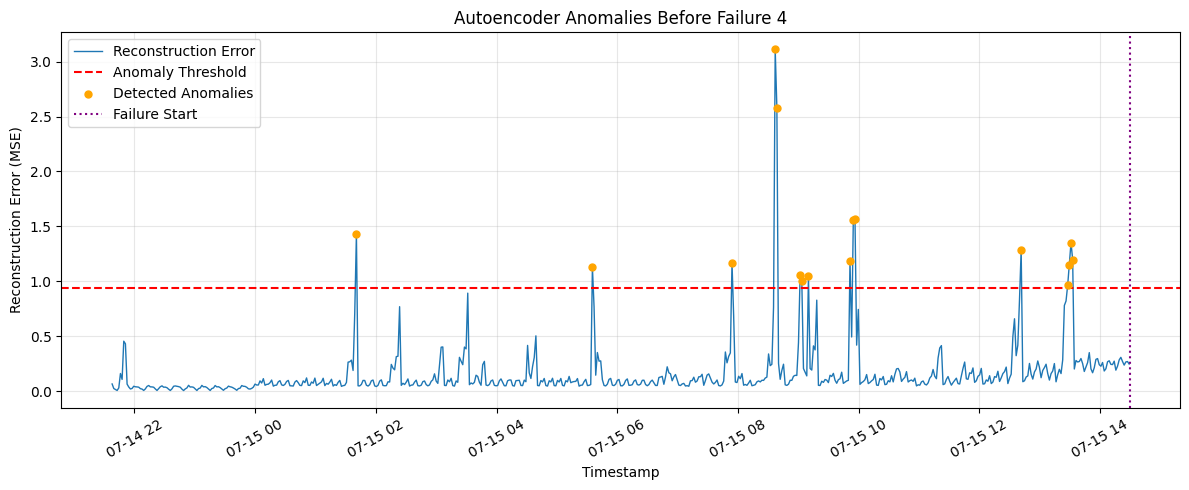

<Figure size 640x480 with 0 Axes>

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    failure_4_pre['timestamp'],
    failure_4_pre['reconstruction_error'],
    label='Reconstruction Error',
    linewidth=1
)

plt.axhline(
    ae_threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.scatter(
    failure_4_alerts['timestamp'],
    failure_4_alerts['reconstruction_error'],
    color='orange',
    s=25,
    label='Detected Anomalies',
    zorder=3
)

plt.axvline(
    failure_4_start,
    color='purple',
    linestyle=':',
    label='Failure Start'
)

plt.title('Autoencoder Anomalies Before Failure 4')
plt.xlabel('Timestamp')
plt.ylabel('Reconstruction Error (MSE)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder Anomalies Before Failure 4.png',
    dpi=300,
    bbox_inches='tight'
)

##### Observation:
##### I examined the anomalies detected before Failure 4.
##### The model identified 16 anomalous windows during the previous 24 hours.
##### Some anomalies appeared individually, while others occurred close together.
##### The highest reconstruction error was 3.1112 at 08:37. Four consecutive windows were flagged between 13:27 and 13:32, around one hour before the failure.
##### These may indicate unusual sensor behaviour before the failure, but further analysis is needed.

## Step 10 : Compare the autoencoder with Isolation Forest

In [36]:
# Load Isolation Forest evaluation scores
baseline_dir = data_dir.parent / 'isolation_forest_results'

if_eval_scores = np.load(
    baseline_dir / 'eval_scores.npy'
)

print("Isolation Forest evaluation scores:", if_eval_scores.shape)
print("Autoencoder evaluation scores:", eval_errors.shape)
print("Evaluation metadata rows:", len(eval_metadata))

Isolation Forest evaluation scores: (954384,)
Autoencoder evaluation scores: (94307,)
Evaluation metadata rows: 954384


In [37]:
# Save failure evaluation results
failure_results_df.to_csv(
    autoencoder_dir / 'failure_results.csv',
    index=False
)

# Save detection timing results
detection_results_df.to_csv(
    autoencoder_dir / 'detection_timing.csv',
    index=False
)

# Save pre-failure analysis
pre_failure_results_df.to_csv(
    autoencoder_dir / 'pre_failure_results.csv',
    index=False
)

# Save window-level evaluation results
eval_window_metadata.to_csv(
    autoencoder_dir / 'eval_window_results.csv',
    index=True
)

# Save Failure 4 alerts
failure_4_alerts.to_csv(
    autoencoder_dir / 'failure_4_pre_failure_alerts.csv',
    index=True
)

print("All evaluation results saved successfully.")

All evaluation results saved successfully.


In [39]:
required_files = [
    'autoencoder_model.keras',
    'training_history.json',
    'train_errors.npy',
    'val_errors.npy',
    'eval_errors.npy',
    'ae_threshold.npy',
    'train_predictions.npy',
    'val_predictions.npy',
    'eval_predictions.npy',
    'failure_results.csv',
    'detection_timing.csv',
    'pre_failure_results.csv',
    'eval_window_results.csv',
    'failure_4_pre_failure_alerts.csv'
]

for filename in required_files:
    path = autoencoder_dir / filename
    print(f"{filename}: {'Saved' if path.exists() else 'MISSING'}")

autoencoder_model.keras: Saved
training_history.json: Saved
train_errors.npy: MISSING
val_errors.npy: MISSING
eval_errors.npy: MISSING
ae_threshold.npy: Saved
train_predictions.npy: Saved
val_predictions.npy: Saved
eval_predictions.npy: Saved
failure_results.csv: Saved
detection_timing.csv: Saved
pre_failure_results.csv: Saved
eval_window_results.csv: Saved
failure_4_pre_failure_alerts.csv: Saved
